In [ ]:
pip install yfinance

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

In [ ]:
# Descargar datos de un activo: COCA-COLA (KO), para los ultimos 10 años

ko = yf.Ticker("KO")  # obtenemos el ticker de Coca-Cola
data = ko.history(period="10y")  # obtenemos los datos para los últimos 5 años
print(data)

                                Open       High        Low      Close  \
Date                                                                    
2016-09-19 00:00:00-04:00  30.922344  31.076368  30.863669  30.878336   
2016-09-20 00:00:00-04:00  31.032347  31.193705  30.981006  31.054350   
2016-09-21 00:00:00-04:00  31.010347  31.252388  30.878326  31.193710   
2016-09-22 00:00:00-04:00  31.325737  31.545772  31.311068  31.509100   
2016-09-23 00:00:00-04:00  31.399087  31.494434  31.281735  31.347746   
...                              ...        ...        ...        ...   
2026-09-10 00:00:00-04:00  88.054572  88.432315  87.279200  87.309021   
2026-09-11 00:00:00-04:00  87.915401  88.124154  87.289133  87.766289   
2026-09-14 00:00:00-04:00  89.466146  89.824011  88.342851  88.820000   
2026-09-15 00:00:00-04:00  88.529999  88.900002  87.800003  88.709999   
2026-09-16 00:00:00-04:00  88.480003  88.660004  87.739998  87.870003   

                             Volume  Dividends  St

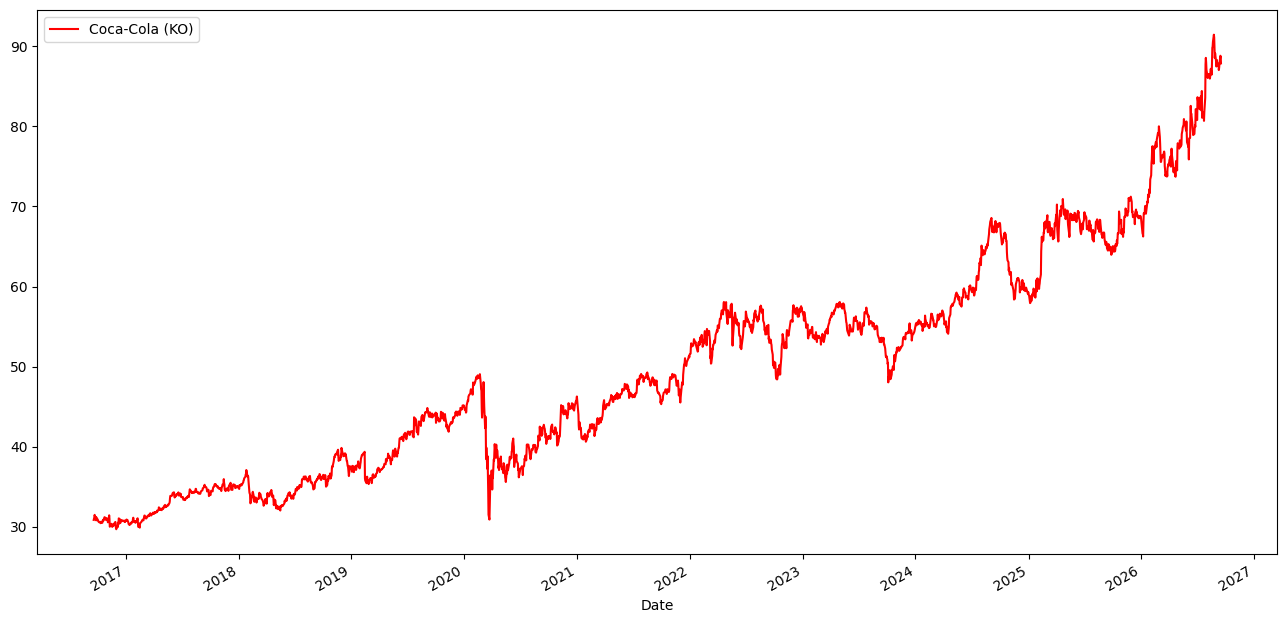

In [ ]:
# Representa gráficamente los datos del precio de cierre

data['Close'].plot(figsize=(16,8), label="Coca-Cola (KO)", color='r')
plt.legend()
plt.show()

**Interpretación**

Coca-Cola es una acción defensiva de consumo básico: el precio no muestra grandes saltos bruscos como los de un banco, sino una tendencia mucho más suave y estable. Durante el shock de marzo de 2020 el precio cae con el mercado, pero recupera con rapidez porque la demanda de sus productos apenas se resiente en una recesión. A partir de ahí la cotización sigue una senda alcista moderada y bastante constante, propia de una empresa madura, con beneficios estables y una política de dividendo creciente sostenida durante décadas (es una "dividend king"). No se observan los subidas rápidas en poco tiempo ni los desplomes profundos típicos de sectores cíclicos como la banca; el patrón esperado es de crecimiento gradual con correcciones limitadas.

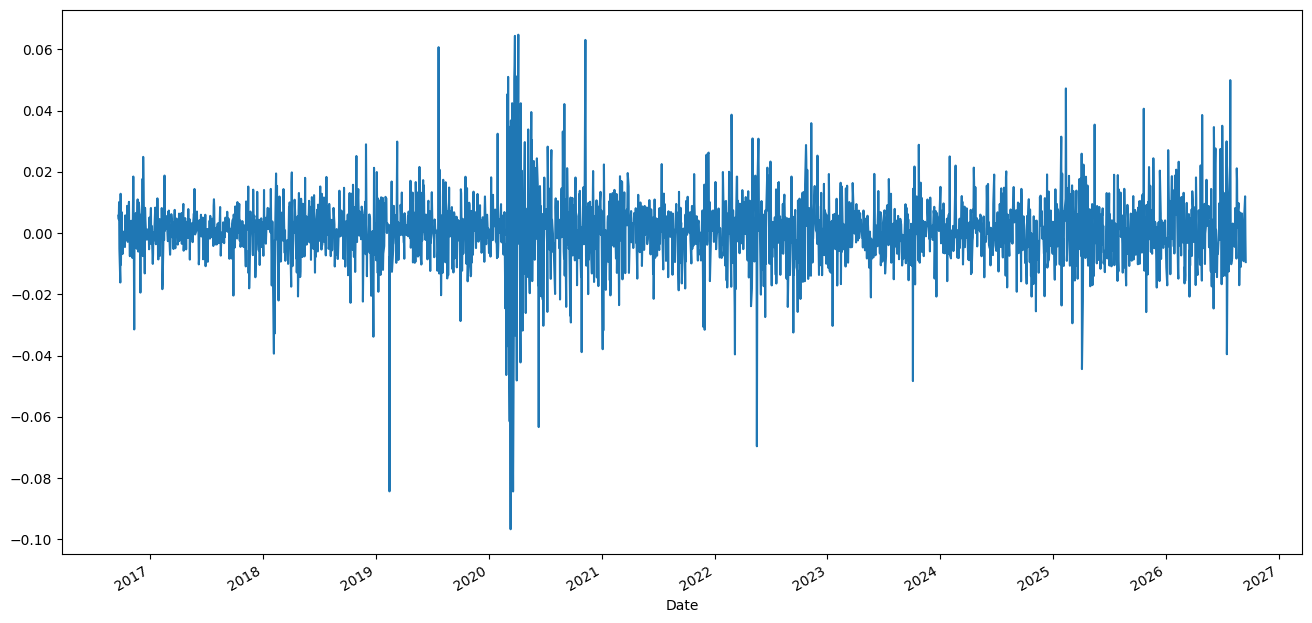

In [ ]:
# Calcula y representa la rentabilidad diaria del activo

day_rent = data['Close'].pct_change()  # rentabilidad del precio de cierre, calcula el cambio porcentual de un dato a otro

day_rent.plot(figsize=(16,8))
plt.show()

**INTERPRETACIÓN**

Las rentabilidades diarias oscilan alrededor de cero, como es habitual en cualquier activo. Al ser Coca-Cola un valor defensivo y de baja volatilidad, cabe esperar que la dispersión de estas oscilaciones sea reducida: los picos extremos (positivos o negativos) deberían ser poco frecuentes y de magnitud limitada. Aun así, seguirán apareciendo saltos puntuales coincidiendo con la publicación de resultados trimestrales o con shocks generales de mercado (como el de 2020), que son los episodios que más contribuyen a la volatilidad acumulada del activo.

Define la función de **rentabilidad anualizada**:
$r_{periodo} = (1+r)^n -1$

In [ ]:
# Función para calcular rentabilidades anualizadas

def rtb_anualizada(tipo, n, p0, p1, dias_habiles):  # n es cuanto tenemos (5 años), y dependerá de si tenemos días, meses o años
  if tipo == 'd':
    r = (p1-p0)/p0
    return ((1+r)**(dias_habiles/n))-1

  if tipo == 'm':
    r = (p1-p0)/p0
    return ((1+r)**(12/n))-1

  if tipo == 'y':  # si tenemos rentabilidades en términos de años (rentabilidad a 5 años, rent activa)
    r = (p1-p0)/p0
    return ((1+r)**(1/n))-1

  else:
    print("Por favor, introduzca 'd', 'm' o 'y' en el tipo")
    return

In [ ]:
# Calcula la rentabilidad media, la rentabilidad activa y la rentabilidad anual del periodo.

rent_media = day_rent.mean()  # después de haber calculado antes con .pct_change() hacemos media. CUIDADO!! está en datos diarios!!!

rent_activa = (data['Close'].iloc[-1]-data['Close'].iloc[0])/data['Close'].iloc[0]  # [-1] ULTIMO Y [0] PRIMERO

rent_anual = rtb_anualizada('y', 5, data['Close'].iloc[0], data['Close'].iloc[-1], 252)  # rentabilidad de un único periodo (principio a fin), un solo valor

print("Rentabilidad Media: ", rent_media, "\nRentabilidad Activa: ", rent_activa, "\nRentabilidad Anual: ", rent_anual)

Rentabilidad Media:  0.0005540910897345824 
Rentabilidad Activa:  0.8684339732788549 
Rentabilidad Anual:  0.13317125962386456


**INTERPRETACIÓN**

Para Coca-Cola cabe esperar una **rentabilidad media diaria** discreta, coherente con un valor de bajo crecimiento pero también de bajo riesgo. La **rentabilidad activa** (acumulada en los 5 años) debería reflejar una revalorización moderada, típica de una compañía madura que reparte gran parte de su beneficio en dividendos en lugar de reinvertirlo agresivamente en crecimiento. La **rentabilidad anual** compuesta será, previsiblemente, contenida en comparación con valores más cíclicos, lo cual tiene sentido: menor riesgo (menor volatilidad) suele ir de la mano de una rentabilidad esperada también menor, en línea con la relación rentabilidad-riesgo estudiada en el tema teórico.

In [ ]:
# Calcula la volatilidad del activo financiero.
cuasivarianza = day_rent.var()  # por defecto pilla la ddof = 1
varianza = day_rent.var(ddof=0)

cuasidesviacion = day_rent.std()
desviacion = day_rent.std(ddof=0)

**Volatilidad anualizada**: $\sigma\sqrt{n}$

In [ ]:
# Anualiza la volatilidad (desviación)

volatilidad_anualizada = desviacion * np.sqrt(252)  # 252 días de cotización en un año
volatilidad_anualizada

np.float64(0.16661087106836175)

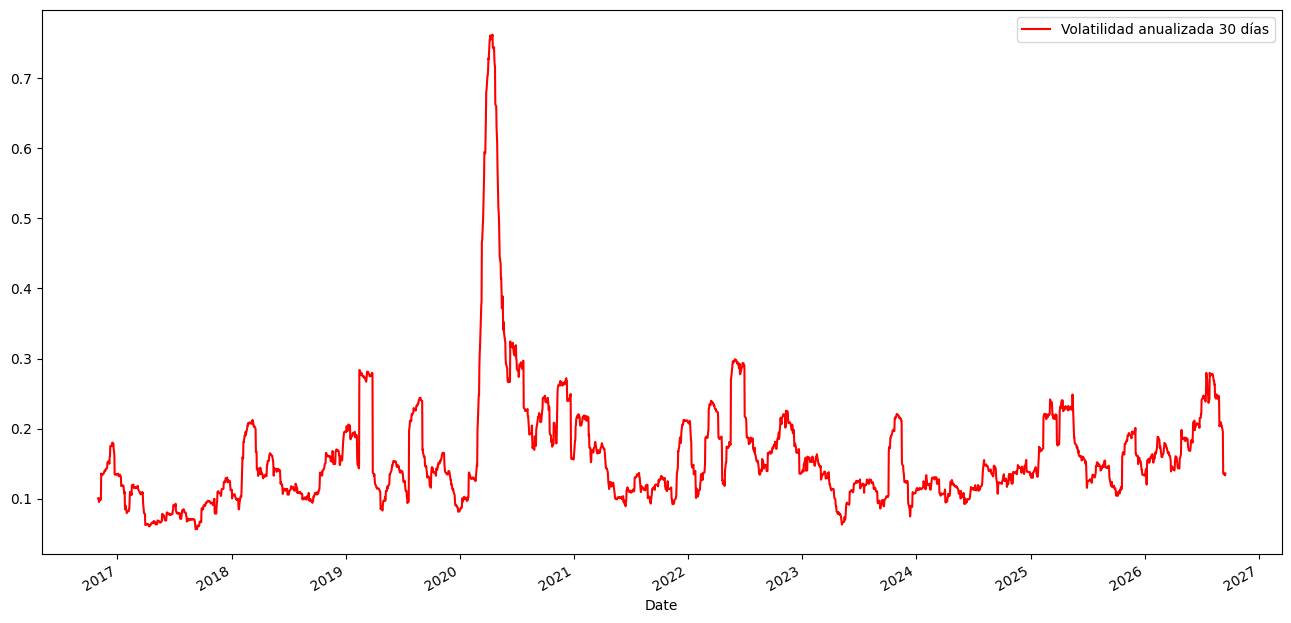

In [ ]:
# Hay veces que es interesante ver como va evolucionando la volatilidad de un activo. Calcula la secuencia de volatilidades a 30 días.

ventana = day_rent.rolling(30)  # ventana de 30 días: para cada punto se consideran los 30 días anteriores
volatilidad_ventana = ventana.std(ddof=0) * np.sqrt(252)  # volatilidad de cada ventana (diaria) anualizada
volatilidad_ventana.plot(figsize=(16,8), color='r', label='Volatilidad anualizada 30 días')
plt.legend()
plt.show()

**INTERPRETACIÓN**

Es previsible que la volatilidad anualizada de 30 días de Coca-Cola muestre un pico marcado en 2020, coincidiendo con la incertidumbre generalizada de mercado por la pandemia, igual que le ocurre a prácticamente cualquier activo cotizado en ese periodo. Sin embargo, a diferencia de un valor bancario, cabe esperar que fuera de ese episodio puntual la volatilidad se mantenga en niveles bajos y bastante estables a lo largo de todo el periodo, sin los repuntes recurrentes ligados a tipos de interés o resultados sectoriales que sí afectan con fuerza a la banca. Este comportamiento sería coherente con el perfil defensivo de la compañía.

**Ratio de Sharpe**: $S_h = \frac{r-r_f}{\sigma}$

In [ ]:
# Ratio de Sharpe.

def ratio_sharpe(precios, rf, tipo_datos):
  sharpe = (rtb_anualizada(tipo_datos, len(precios.index), precios.iloc[0], precios.iloc[-1], 252) - rf) / (day_rent.std(ddof=0) * np.sqrt(252))
  return sharpe

In [ ]:
ratio_sharpe(data['Close'], 0, 'd')

np.float64(0.6003757268485296)

**INTERPRETACIÓN**

Un ratio de Sharpe positivo indica que el activo ha compensado, con rentabilidad extra, el riesgo asumido por unidad de volatilidad. En el caso de Coca-Cola, al combinar una rentabilidad moderada con una volatilidad baja, el ratio podría resultar comparable o incluso superior al de valores de mayor riesgo si estos no han conseguido una rentabilidad proporcionalmente mayor: el Sharpe no premia la rentabilidad en términos absolutos, sino la rentabilidad obtenida por cada unidad de riesgo asumido.

$Drawdown_i = \frac{p_i}{p_{max}} - 1$

$Max-drawdown = min(drawdown_i)_n$

In [ ]:
# DRAWDOWN

def drawdown(precios, plot):
  if plot == 1:  # drawdown de rendimientos
    rtb = precios.pct_change().dropna()  # calcular rentabilidad
    roll_max = rtb.rolling(center=False, min_periods=1, window=252).max()  # ventana móvil: máximo de los últimos 252 días
    daily_draw_down = rtb / roll_max - 1  # fórmula (con el -1)

    max_daily_draw_down = daily_draw_down.rolling(center=False, min_periods=1, window=252).min()  # mínimo (mayor caída) en la ventana

    fig, ax = plt.subplots(figsize=(16,8))
    ax.plot(rtb.index, daily_draw_down, label="Daily drawdown")
    ax.plot(rtb.index, max_daily_draw_down, label="Maximum daily draw down in time window")
    ax.legend()
    plt.show()

    return daily_draw_down, max_daily_draw_down

  if plot == 2:  # lo mismo pero sobre precios
    roll_max = precios.rolling(center=False, min_periods=1, window=252).max()
    daily_draw_down = precios / roll_max - 1

    max_daily_draw_down = daily_draw_down.rolling(center=False, min_periods=1, window=252).min()

    fig, ax = plt.subplots(figsize=(16,8))
    ax.plot(precios.index, daily_draw_down, label="Daily drawdown")
    ax.plot(precios.index, max_daily_draw_down, label="Maximum daily draw down in time window")
    ax.set_ylim(-0.5, 0.2)
    ax.legend()
    plt.show()

    return daily_draw_down, max_daily_draw_down

  else:  # si no se especifica, se comporta como plot == 1
    rtb = precios.pct_change().dropna()
    roll_max = rtb.rolling(center=False, min_periods=1, window=252).max()
    daily_draw_down = rtb / roll_max - 1

    max_daily_draw_down = daily_draw_down.rolling(center=False, min_periods=1, window=252).min()

    return daily_draw_down, max_daily_draw_down

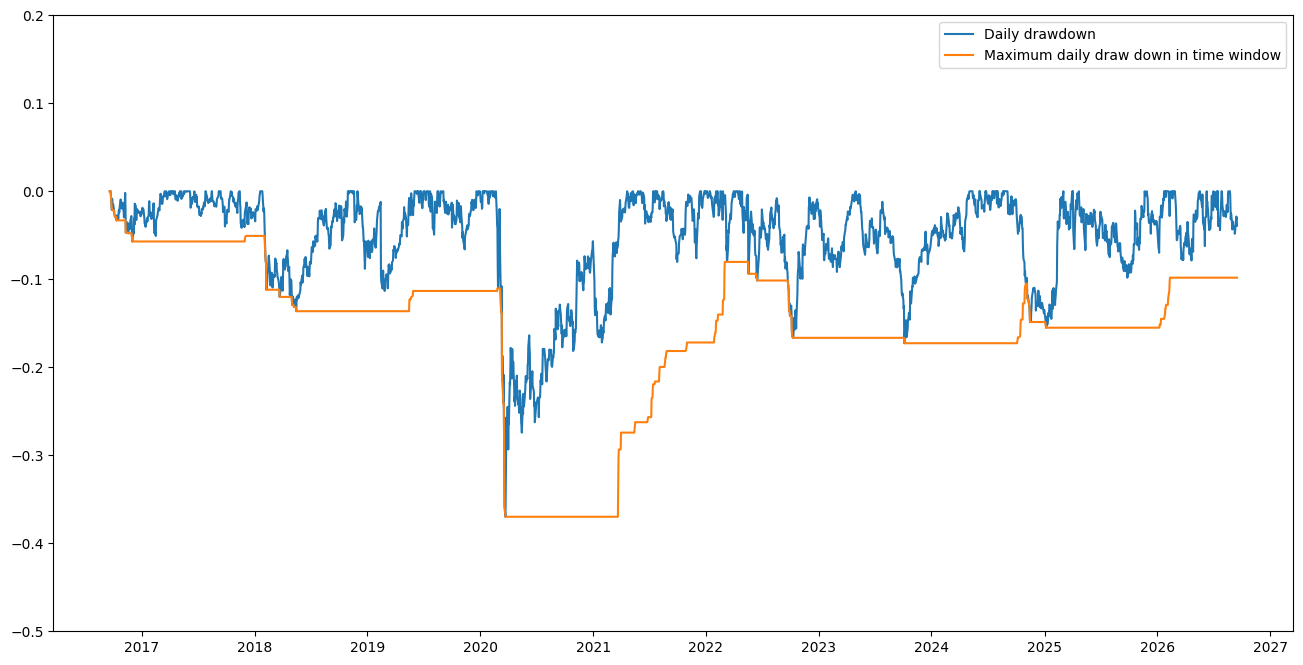

In [32]:
#Gráficar DRAWDOWN

a = drawdown(data['Close'], 2)

**INTERPRETACIÓN**

Se espera que el drawdown de Coca-Cola muestre una caída notable en 2020 (coincidiendo con el shock de mercado), pero de una magnitud menor que en valores más cíclicos, y con una recuperación relativamente rápida de los máximos previos. Fuera de ese episodio, al tratarse de un valor de baja volatilidad y tendencia alcista suave, las caídas desde máximos deberían ser poco profundas y de corta duración, reflejando de nuevo el perfil defensivo del activo frente a otros más expuestos al ciclo económico.